# TP4-AdvProgram4DS

**Read our [Gemma 3 blog](https://unsloth.ai/blog/gemma3) for what's new in Unsloth and our [Reasoning blog](https://unsloth.ai/blog/r1-reasoning) on how to train reasoning models.**

Visit our docs for all our [model uploads](https://docs.unsloth.ai/get-started/all-our-models) and [notebooks](https://docs.unsloth.ai/get-started/unsloth-notebooks).


# 0-Check System

Colab Server > GPU > T5 > 2026-10 > Name: VSL-T4-GPU

BUNHENG LOSS = 1.009 (loss validate)

In [14]:
import sys
import subprocess
from importlib import metadata

# 1. Check Python.
print("=== PYTHON ===")
print("Version:", sys.version.split()[0])
print("Location:", sys.executable)

# 2. Check the packages used by our notebook.
print("\n=== PACKAGES ===")

packages = [
    "torch", "torchvision", "unsloth", "unsloth_zoo",
    "transformers", "tokenizers", "datasets", "trl",
    "peft", "accelerate", "bitsandbytes", "triton",
    "xformers", "sentencepiece", "protobuf", "Pillow",
]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"OK       {package:<18} {version}")
    except metadata.PackageNotFoundError:
        print(f"MISSING  {package}")

# 3. Check the NVIDIA GPU.
print("\n=== GPU ===")

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
except FileNotFoundError:
    print("NVIDIA GPU tool was not found. Check the selected kernel.")

# 4. Check whether installed packages have conflicting requirements.
print("\n=== PACKAGE REQUIREMENTS ===")

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)


=== PYTHON ===
Version: 3.13.16
Location: /usr/bin/python3

=== PACKAGES ===
OK       torch              2.11.0+cu130
OK       torchvision        0.26.0+cu130
OK       unsloth            2026.11.2
OK       unsloth_zoo        2026.11.2
OK       transformers       5.17.0
OK       tokenizers         0.23.3
OK       datasets           4.8.5
OK       trl                1.15.0
OK       peft               0.21.2
OK       accelerate         1.15.0
OK       bitsandbytes       0.50.2
OK       triton             3.6.0
OK       xformers           0.0.35
OK       sentencepiece      0.2.2
OK       protobuf           6.33.6
OK       Pillow             11.3.0

=== GPU ===
Thu Nov 12 02:30:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                

In [15]:
# check "is torch GPU version"
import torch

print("PyTorch version:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

    # Do a small calculation on the GPU.
    numbers = torch.tensor([1.0, 2.0, 3.0], device="cuda")
    print("Calculation result:", numbers.sum().item())
    print("Calculation device:", numbers.device)
else:
    print("PyTorch cannot use a GPU in this session.")

PyTorch version: 2.11.0+cu130
CUDA build: 13.0
GPU available: True
GPU name: Tesla T4
Calculation result: 6.0
Calculation device: cuda:0


# 1-Installation

### Installation

In [16]:
# # Install training tool - First time run
# import sys
# import subprocess

# # Use fixed versions so our setup is easier to check.
# packages = [
#     "torch==2.11.0+cu130",
#     "torchvision==0.26.0+cu130",
#     "unsloth==2026.11.2",
#     "unsloth_zoo==2026.11.2",
#     "transformers==5.17.0",
#     "trl==1.15.0",
#     "bitsandbytes==0.50.2",
#     "huggingface-hub<2",
#     "requests==2.32.4",
#     "Pillow==11.3.0",
#     "jedi",
# ]

# # Download xformers built for our PyTorch and CUDA setup.
# xformers_wheel = (
#     "https://download.pytorch.org/whl/cu130/"
#     "xformers-0.0.35-py39-none-manylinux_2_28_x86_64.whl"
# )
# packages.append(xformers_wheel)

# # Install into the Python that runs this notebook.
# subprocess.check_call(
#     [sys.executable, "-m", "pip", "install", *packages]
# )

# print("Installation finished.")
# print("To comfirm please ReRun the system check !")

# 2.Unsloth

`FastModel` supports loading nearly any model now! This includes Vision and Text models!

In [17]:
from unsloth import FastModel # fast model is for load and preppare the model
import torch

fourbit_models = [
    # 4bit dynamic quants for superior accuracy and low memory use
    "unsloth/gemma-3-1b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-4b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-12b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-27b-it-unsloth-bnb-4bit",

    # Other popular models!
    "unsloth/Llama-3.1-8B",
    "unsloth/Llama-3.2-3B",
    "unsloth/Llama-3.3-70B",
    "unsloth/mistral-7b-instruct-v0.3",
    "unsloth/Phi-4",
] # More models at https://huggingface.co/unsloth

model, tokenizer = FastModel.from_pretrained(
    model_name = "unsloth/gemma-3-4b-it",
    max_seq_length = 2048, # Choose any for long context!
    load_in_4bit = True,  # 4 bit quantization to reduce memory
    load_in_8bit = False, # [NEW!] A bit more accurate, uses 2x memory
    full_finetuning = False, # [NEW!] We have full finetuning now!
    # token = "hf_...", # use one if using gated models
)

==((====))==  Unsloth 2026.11.2: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

We now add LoRA adapters so we only need to update a small amount of parameters!

In [18]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers     = False, # Turn off for just text!
    finetune_language_layers   = True,  # Should leave on!
    finetune_attention_modules = True,  # Attention good for GRPO, Include attention parts (parts that connect information across tokens)
    finetune_mlp_modules       = True,  # SHould leave on always!

    r = 8,           # Larger = higher accuracy, but might overfit
    lora_alpha = 8,  # Recommended alpha == r at least
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
)

# 3.Data Prep
<a name="Data"></a>
### Data Prep
We now use the `Gemma-3` format for conversation style finetunes. We use [Maxime Labonne's FineTome-100k](https://huggingface.co/datasets/mlabonne/FineTome-100k) dataset in ShareGPT style. Gemma-3 renders multi turn conversations like below:

```
<bos><start_of_turn>user
Hello!<end_of_turn>
<start_of_turn>model
Hey there!<end_of_turn>
```

We use our `get_chat_template` function to get the correct chat template. We support `zephyr, chatml, mistral, llama, alpaca, vicuna, vicuna_old, phi3, llama3, phi4, qwen2.5, gemma3` and more.

In [19]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)
print("Gemma 3 message format is ready.")

Gemma 3 message format is ready.


## A. Import DataSet

In [20]:
# from datasets import load_dataset
# dataset = load_dataset('csv',data_files="dataasilida_cleaned.csv")

In [21]:
# existing code loads data; it does not fix these problems. this code expects separate input and output columns, so it would fail.
# The checking cell is just an extra step to help see the problem. After clean the CSV, we can use the existing load_dataset code (above, cell10).

import csv
from pathlib import Path
from collections import Counter

csv_path = Path("/content/dataasilida_cleaned.csv")

if not csv_path.exists():
    raise FileNotFoundError("Upload the CSV to Colab first.")

with csv_path.open(encoding="utf-8-sig", newline="") as file:
    reader = csv.reader(file)
    header = next(reader, [])
    raw_rows = list(reader)

from collections import Counter

wrong_columns = []
missing_inputs = []
missing_outputs = []
seen_pairs = {}
duplicate_rows = []
checked_rows = 0

for record_number, row in enumerate(raw_rows, start=2):
    if len(row) != 2:
        wrong_columns.append(record_number)
        continue

    checked_rows += 1

    question = row[0].strip()
    answer = row[1].strip()

    if not question:
        missing_inputs.append(record_number)

    if not answer:
        missing_outputs.append(record_number)

    pair = (question, answer)

    if pair in seen_pairs:
        first_record = seen_pairs[pair]
        duplicate_rows.append((first_record, record_number))
    else:
        seen_pairs[pair] = record_number

print("=== COLUMNS ===")
print("Expected:", ["input", "output"])
print("Found:", header)
print("Correct header:", header == ["input", "output"])

print("\n=== ROW STRUCTURE ===")
print("Total data rows:", len(raw_rows))
print("Rows without exactly two fields:", len(wrong_columns))
print("Affected records:", wrong_columns)

print("\n=== MISSING VALUES ===")
print("Rows checked:", checked_rows)
print("Rows not checked:", len(wrong_columns))
print("Missing input in checked rows:", len(missing_inputs))
print("Missing output in checked rows:", len(missing_outputs))
print("Records with missing input:", missing_inputs)
print("Records with missing output:", missing_outputs)

print("\n=== DUPLICATES ===")
print("Extra repeated pairs:", len(duplicate_rows))
print("Rows not checked:", len(wrong_columns))

for first_record, repeated_record in duplicate_rows:
    print(f"Record {repeated_record} repeats record {first_record}.")

if not duplicate_rows:
    print("No duplicates found among checked rows.")

if header != ["input", "output"] or wrong_columns:
    print("\nStructure needs fixing. Repeat all checks after fixing it.")
else:
    print("\nStructure checks passed.")

=== COLUMNS ===
Expected: ['input', 'output']
Found: ['input,output']
Correct header: False

=== ROW STRUCTURE ===
Total data rows: 521
Rows without exactly two fields: 7
Affected records: [98, 99, 101, 393, 395, 419, 424]

=== MISSING VALUES ===
Rows checked: 514
Rows not checked: 7
Missing input in checked rows: 0
Missing output in checked rows: 0
Records with missing input: []
Records with missing output: []

=== DUPLICATES ===
Extra repeated pairs: 2
Rows not checked: 7
Record 85 repeats record 79.
Record 224 repeats record 213.

Structure needs fixing. Repeat all checks after fixing it.


## B. Clean Dataset

### 1. Handle Columns

In [22]:
header = header[0].split(",")
print(header)

['input', 'output']


### 2.Handle Missing value

In [23]:
# Combine record numbers without listing the same record twice.
missing_records = sorted(set(missing_inputs + missing_outputs))

print("=== RECORDS WITH CONFIRMED MISSING VALUES ===")

if not missing_records:
    print("No empty input or output found among the checked rows.")

for record_number in missing_records:
    row = raw_rows[record_number - 2]

    print(f"\nRecord {record_number}")
    print("Input:", row[0] if row[0].strip() else "[MISSING]")
    print("Output:", row[1] if row[1].strip() else "[MISSING]")

print("\n=== RECORDS WITH WRONG STRUCTURE ===")
print("These still need checking for missing values.")

if not wrong_columns:
    print("None.")

for record_number in wrong_columns:
    row = raw_rows[record_number - 2]

    print(f"\nRecord {record_number}")
    print("Number of fields:", len(row))

    for position, value in enumerate(row, start=1):
        print(f"Field {position}:", value)

=== RECORDS WITH CONFIRMED MISSING VALUES ===
No empty input or output found among the checked rows.

=== RECORDS WITH WRONG STRUCTURE ===
These still need checking for missing values.

Record 98
Number of fields: 1
Field 1: តើប័ណ្ណនិម្មិតអេស៊ីលីដា មានកំណត់ទំហំទឹកប្រាក់ និងចំនួនប័ណ្ណ ដែរ ឬទេ ? ,លោក-អ្នកអាចបង្កើតប័ណ្ណនិម្មិតអេស៊ីលីដា ដែលមានទំហំប្រតិបត្តិការប្រចាំថ្ងៃរហូតដល់ ៥០០០ដុល្លារអាមេរិក ក្នុងមួយប័ណ្ណ និងអាចបង្កើតតាមសេវាអេស៊ីលីដាម៉ូបាលក្នុងមួយគណនី ចំនួន ១០ប័ណ្ណ ។

Record 99
Number of fields: 1
Field 1: តើប័ណ្ណនិម្មិតអេស៊ីលីដា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេលប៉ុន្មាន ? ,ប័ណ្ណនិម្មិតអេស៊ីលីដា មានសុពលភាពប្រើប្រាស់ ៣ឆ្នាំ ដោយគិតចាប់ពីថ្ងៃបង្កើត ឬបោះពុម្ព ។

Record 101
Number of fields: 1
Field 1: តើការបង្កើតប័ណ្ណនិម្មិតអេស៊ីលីដា មានគិតថ្លៃសេវា ដែរ ឬទេ ? ,ការបង្កើតប័ណ្ណនិម្មិតអេស៊ីលីដា គឺ មិនមានគិតថ្លៃសេវាទេ ។

Record 393
Number of fields: 1
Field 1: តើសាធារណជនអាចប្តូរប្រាក់នៅឯធនាគារជាតិនៃកម្ពុជាបានឬទេ ? ,អ្នកអាចប្តូរប្រាក់រៀល ឬកាសនៅធនាគារជាតិនៃកម្ពុជាបាន ។ ធនាគារជាតិនៃកម្ពុជា នឹងធ្

In [24]:
# we found that those are just combined of 2 columns, not  missing value,
# make it go to the right colums

fixed_count = 0
unresolved_records = []

for record_number in wrong_columns:
    row = raw_rows[record_number - 2]

    # Leave rows already fixed unchanged.
    if len(row) == 2:
        continue

    if len(row) != 1:
        unresolved_records.append(record_number)
        continue

    text = row[0]

    # First, try separating at the first comma.
    question, separator, answer = text.partition(",")

    # If there is no comma, try the first question mark.
    if not separator:
        question, separator, answer = text.partition("?")

        if separator:
            question += "?"

    question = question.strip()
    answer = answer.strip()

    if not separator or not question or not answer:
        unresolved_records.append(record_number)
        continue

    raw_rows[record_number - 2] = [question, answer]
    fixed_count += 1

    print(f"\n=== FIXED RECORD {record_number} ===")
    print("Input:", question)
    print("Output:", answer)

print("\nFixed records:", fixed_count)
print("Records still needing inspection:", unresolved_records)


=== FIXED RECORD 98 ===
Input: តើប័ណ្ណនិម្មិតអេស៊ីលីដា មានកំណត់ទំហំទឹកប្រាក់ និងចំនួនប័ណ្ណ ដែរ ឬទេ ?
Output: លោក-អ្នកអាចបង្កើតប័ណ្ណនិម្មិតអេស៊ីលីដា ដែលមានទំហំប្រតិបត្តិការប្រចាំថ្ងៃរហូតដល់ ៥០០០ដុល្លារអាមេរិក ក្នុងមួយប័ណ្ណ និងអាចបង្កើតតាមសេវាអេស៊ីលីដាម៉ូបាលក្នុងមួយគណនី ចំនួន ១០ប័ណ្ណ ។

=== FIXED RECORD 99 ===
Input: តើប័ណ្ណនិម្មិតអេស៊ីលីដា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេលប៉ុន្មាន ?
Output: ប័ណ្ណនិម្មិតអេស៊ីលីដា មានសុពលភាពប្រើប្រាស់ ៣ឆ្នាំ ដោយគិតចាប់ពីថ្ងៃបង្កើត ឬបោះពុម្ព ។

=== FIXED RECORD 101 ===
Input: តើការបង្កើតប័ណ្ណនិម្មិតអេស៊ីលីដា មានគិតថ្លៃសេវា ដែរ ឬទេ ?
Output: ការបង្កើតប័ណ្ណនិម្មិតអេស៊ីលីដា គឺ មិនមានគិតថ្លៃសេវាទេ ។

=== FIXED RECORD 393 ===
Input: តើសាធារណជនអាចប្តូរប្រាក់នៅឯធនាគារជាតិនៃកម្ពុជាបានឬទេ ?
Output: អ្នកអាចប្តូរប្រាក់រៀល ឬកាសនៅធនាគារជាតិនៃកម្ពុជាបាន ។ ធនាគារជាតិនៃកម្ពុជា នឹងធ្វើការផ្លាស់ ប្តូរជូនអ្នកដោយមិនគិតកម្រៃសេវា នូវក្រដាសប្រាក់រៀលដែលចាស់ឬរហែក ឬអ្នកអាចប្តូរពីក្រដាស ប្រាក់ ដែលមានចំនួនទឹកប្រាក់ធំទៅជាក្រដាសប្រាក់ដែលមានចំនួនទឹកប្រាក់តូចជាងមុន ឬពីតូចទៅធំ ទៅតាមតម

### 3.Handle Duplicate

In [25]:
# display duplicate
seen_pairs = {}
duplicate_rows = []

for record_number, row in enumerate(raw_rows, start=2):
    if len(row) != 2:
        raise ValueError(f"Fix record {record_number} first.")

    pair = (row[0].strip(), row[1].strip())

    if pair in seen_pairs:
        first_record = seen_pairs[pair]
        duplicate_rows.append((first_record, record_number))
    else:
        seen_pairs[pair] = record_number

print("Extra repeated pairs:", len(duplicate_rows))

for first_record, repeated_record in duplicate_rows:
    row = raw_rows[repeated_record - 2]

    print(f"\nRecord {repeated_record} repeats record {first_record}.")
    print("Input:", row[0])
    print("Output:", row[1])

if not duplicate_rows:
    print("No duplicates found.")

Extra repeated pairs: 2

Record 85 repeats record 79.
Input: តើសេវាអេស៊ីលីដា អ៊ីខុមមើស ផ្តល់អត្ថប្រយោជន៍អ្វីខ្លះ ដល់ពាណិជ្ជករដែលជាម្ចាស់វេបសាយលក់ទំនិញ-សេវាកម្ម
Output: ផ្តល់កេរ្តិ៍ឈ្មោះល្អ និងទទួលស្គាល់ពីអតិថិជនគ្រប់ទិសទី តាមរយៈការលក់ទំនិញតាមប្រព័ន្ធអ៊ីនធើណែត និងទូទាត់តាមប័ណ្ណឥណពន្ធ ឬប័ណ្ណឥណទាន។ \n បង្កើនបរិមាណនៃការលក់ផលិតផល-សេវាកម្ម ឲ្យកាន់តែទូលំទូលាយ។ \n បម្រើសេវារហ័ស និងកាត់បន្ថយពេលវេលាលើការទទួលសាច់ប្រាក់។ \n មានបំពាក់ប្រព័ន្ធសុវត្ថិភាព នៅលើវេបសាយលក់ទំនិញ ដែលមានសុវត្ថិភាពខ្ពស់ចៀសវាងការលួចបន្លំផ្សេងៗ។ \n អាចត្រួតពិនិត្យរបាយការណ៍ និងតាមដានការបង់ប្រាក់បានភ្លាមៗនៅក្នុងប្រព័ន្ធអេស៊ីលីដាអ៊ីខុមមើស។ \n ផ្តល់ភាពងាយស្រួលដល់អតិថិជនរបស់ក្រុមហ៊ុន/អង្គភាព ក្នុងការបញ្ជាទិញ/ទូទាត់ថ្លៃទំនិញ ពីចម្ងាយដោយមិនចាំបាច់ធ្វើដំណើរទៅហាងទំនិញ ហើយបានទទួលទំនិញនៅតាមអាសយដ្ឋានរបស់ខ្លួន។

Record 224 repeats record 213.
Input: តើមូលប្បទានបត្រមួយក្បាលថ្លៃប៉ុន្មាន 
Output: គិតថ្លៃ KHR 20000 USD5 THB200 ឬសមមូលលើការជាវមូលប្បទានបត្រមួយក្បាល (មួយក្បាលមាន 25សន្លឹក) ។ សម្រាប់អតិថិជនដែលបើកគណនីថ្មីដំបូង គឺមិនគិតថ្លៃសេវាលើការជាវ

In [26]:
# keep 1 copy of them 
seen_pairs = set()
clean_rows = []
removed_count = 0

for record_number, row in enumerate(raw_rows, start=2):
    if len(row) != 2:
        raise ValueError(f"Fix record {record_number} first.")

    question = row[0].strip()
    answer = row[1].strip()
    pair = (question, answer)

    if pair in seen_pairs:
        removed_count += 1
        continue

    seen_pairs.add(pair)
    clean_rows.append([question, answer])

print("Original rows:", len(raw_rows))
print("Extra copies removed:", removed_count)
print("Clean rows:", len(clean_rows))

Original rows: 521
Extra copies removed: 2
Clean rows: 519


### 3A-Verify Dataset


In [27]:
bad_rows = []
missing_inputs = []
missing_outputs = []
seen_pairs = set()
duplicate_count = 0

for row_number, row in enumerate(clean_rows, start=1):
    if len(row) != 2:
        bad_rows.append(row_number)
        continue

    question = row[0].strip()
    answer = row[1].strip()

    if not question:
        missing_inputs.append(row_number)

    if not answer:
        missing_outputs.append(row_number)

    pair = (question, answer)

    if pair in seen_pairs:
        duplicate_count += 1

    seen_pairs.add(pair)

print("=== CLEAN DATA CHECK ===")
print("Total rows:", len(clean_rows))
print("Wrong structure:", bad_rows)
print("Extra repeated pairs:", duplicate_count)

if not clean_rows:
    print("The clean dataset is empty.")
elif bad_rows or missing_inputs or missing_outputs or duplicate_count:
    print("Some problems still need fixing.")
else:
    print("Clean data checks passed.")

=== CLEAN DATA CHECK ===
Total rows: 519
Wrong structure: []
Extra repeated pairs: 0
Clean data checks passed.


### 5-Save dataset and reimport

In [28]:
import csv

clean_path = csv_path.with_name("dataasilida_cleaned_v2.csv")

with clean_path.open(
    "w", encoding="utf-8", newline=""
) as file:
    writer = csv.writer(file)

    # Write the column names.
    writer.writerow(header)

    # Write the cleaned data.
    writer.writerows(clean_rows)

print("Saved file:", clean_path)
print("Saved data rows:", len(clean_rows))

Saved file: /content/dataasilida_cleaned_v2.csv
Saved data rows: 519


In [29]:
from datasets import load_dataset

clean_path = csv_path.with_name("dataasilida_cleaned_v2.csv")

dataset = load_dataset(
    "csv",
    data_files=str(clean_path),
)

print(dataset)
print("Columns:", dataset["train"].column_names)
print("Rows:", len(dataset["train"]))

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input', 'output'],
        num_rows: 519
    })
})
Columns: ['input', 'output']
Rows: 519


In [30]:
print("=== DATASET DETAILS ===")

for group_name in ["train", "validation", "test"]:
    if group_name in dataset:
        group = dataset[group_name]

        print(f"\nGroup: {group_name}")
        print("Rows:", len(group))
        print("Columns:", group.column_names)
    else:
        print(f"\nGroup: {group_name} — not created")

=== DATASET DETAILS ===

Group: train
Rows: 519
Columns: ['input', 'output']

Group: validation — not created

Group: test — not created


In [31]:
dataset['train']['input'][0]

'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី'

## C. prepares a function that turns each question-and-answer pair into a conversation.

In [32]:
def formatting_prompts_func(examples):
    instructions = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, output in zip(instructions, outputs):
      messages = [
        {
            "role": "user", 'content': instruction.strip(" ")
          },
          {
            "role": "assistant", 'content': output
          }
      ]
      #tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      text = tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      texts.append(text)
    return {"text":texts}



#### What is Batch = True ?

For example, the function receives something like:

examples = {
    "input": ["Hello", "What is Python?"],
    "output": ["Hi!", "A programming language."],
}

Your function then pairs them:

Hello            → Hi!
What is Python?  → A programming language.

We use it because cell 36 is written to handle lists of questions and answers, using:

for instruction, output in zip(instructions, outputs):

With batched=False, the function would receive one row at a time:

examples = {
    "input": "Hello",
    "output": "Hi!",
}

That does not fit your current function: it would loop through the text’s characters instead of a list of examples.

Keep batched=True for this function. This is a group for preparing data; the training group size is a separate setting.

In [33]:
# Apply our formatting function to the dataset.
# It turns each question-and-answer pair into Gemma 3's message format.
# The result is added as a new column called "text".
dataset = dataset.map(
    formatting_prompts_func,  # The function we created in cell 36.
    batched=True,             # Process a group of rows at a time.
)

# Show the column names: input, output, and the new text column.
print("Columns:", dataset["train"].column_names)

# Show the number of rows. Formatting should keep all 519 rows.
print("Rows:", len(dataset["train"]))

Map:   0%|          | 0/519 [00:00<?, ? examples/s]

Columns: ['input', 'output', 'text']
Rows: 519


Let's see how row 100 looks like!

In [34]:
# Python counts from zero, so position 99 is the 100th row.
row_index = 99

# Show the question from the 100th row.
print(dataset["train"]["input"][row_index])

តើត្រូវមានលក្ខខណ្ឌតម្រូវអ្វីខ្លះ សម្រាប់ការស្នើសុំបង្កើតប័ណ្ណនិម្មិតតាមសេវាអេស៊ីលីដាម៉ូបាល


Let's see how the chat template did! Notice `Gemma-3` default adds a `<bos>`!

In [35]:
# Show the full formatted conversation for the 100th row.
# It includes the question, answer, and special message markers.
print(dataset["train"]["text"][row_index])

<bos><start_of_turn>user
តើត្រូវមានលក្ខខណ្ឌតម្រូវអ្វីខ្លះ សម្រាប់ការស្នើសុំបង្កើតប័ណ្ណនិម្មិតតាមសេវាអេស៊ីលីដាម៉ូបាល<end_of_turn>
<start_of_turn>model
អតិថិជនត្រូវមានគណនីប្រភព (គណនីធនាគារ) ជាប្រាក់ដុល្លារអាមេរិក ដែលបានភ្ជាប់ជាមួយសេវាអេ-ស៊ីលីដាម៉ូបាល។ \n ត្រូវបម្រុងសមតុល្យគណនីឲ្យបានគ្រប់គ្រាន់ រាល់ពេលបង្កើតប័ណ្ណ និងពេលទូទាត់ថ្លៃទំនិញ-សេវាកម្ម ។<end_of_turn>



# 4-Train the Model
<a name="Train"></a>

## A-Prepare Training and Validation Data

> Content: Divide the cleaned examples into two groups.

> Purpose: Keep some examples separate for checking the model.

Use about 90% of the examples for learning.
Keep about 10% separate to check the model during training.

In [36]:
from datasets import DatasetDict

# Split only once. Running this cell again keeps the existing groups.
if "validation" not in dataset:
    split_data = dataset["train"].train_test_split(
        test_size=0.10,  # Keep about 10% for validation.
        seed=3407,       # Make the random choice repeatable.
        shuffle=True,    # Mix the rows before dividing them.
    )

    # The tool calls the smaller group "test".
    # We name it "validation" because that is how we will use it.
    dataset = DatasetDict({
        "train": split_data["train"],
        "validation": split_data["test"],
    })
else:
    print("Training and validation groups already exist.")

# Show the size and columns of each group.
for group_name in ["train", "validation"]:
    print(f"\nGroup: {group_name}")
    print("Rows:", len(dataset[group_name]))
    print("Columns:", dataset[group_name].column_names)


Group: train
Rows: 467
Columns: ['input', 'output', 'text']

Group: validation
Rows: 52
Columns: ['input', 'output', 'text']


## B-Set the Training Settings

> Content: Choose batch size, learning rate, and training steps.

> Purpose: Explain how we want the model to learn.

This section sets the rules the trainer will follow:

- How many examples to process at once.
- How often to update the model’s trainable weights.
- How large each learning change should be.
- How many training steps to run.
- How often to check progress using validation data.
- How often to save training progress.

We store these settings in a variable called `training_args`.

This section only prepares the settings. Training starts later.


In [37]:
from trl import SFTConfig

training_args = SFTConfig(
    # Folder for training results on the Colab computer.
    output_dir="outputs/tp4_gemma3-ep2",

    # Read the formatted conversations from the "text" column.
    dataset_text_field="text",

    # Limit each example to 2,048 tokens (pieces of text).
    max_length=2048,

    # Keep examples separate instead of joining them together.
    packing=False,

    # Process one example at a time to use less GPU memory.
    per_device_train_batch_size=1,

    # Collect learning changes over 8 batches before one update.
    gradient_accumulation_steps=8,

    # Check one validation example at a time.
    per_device_eval_batch_size=1,

    # # Make 60 updates to the trainable weights.
    # max_steps=60,

    #####################################
    num_train_epochs = 2,

    # Increase the learning rate gradually over the first 5 updates.
    warmup_steps=5,

    # Control how large the learning changes are.
    learning_rate=2e-4,  # Same as 0.0002.

    # Choose the tool that updates the weights.
    optim="adamw_8bit",

    # Apply a small penalty that discourages overly large weights.
    weight_decay=0.01,

    # Reduce the learning rate steadily after warmup.
    lr_scheduler_type="linear",

    # Follow the loader's float32 requirement for our Gemma 3 setup.
    fp16=False,
    bf16=False,

    # Record training loss after every update.
    logging_steps=1,

    # Measure validation loss after every 10 updates.
    eval_strategy="steps",
    eval_steps=10,

    # During validation, return loss without keeping prediction results.
    prediction_loss_only=True,

    # Save a checkpoint (saved training state) every 10 updates.
    save_strategy="steps",
    save_steps=10,

    # Keep only the two most recent checkpoints.
    save_total_limit=2,

    # Make random choices easier to repeat.
    seed=3407,

    # Keep external reporting services turned off.
    report_to="none",

    # Finish with the saved model that had the lowest validation loss.
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

print("Training settings are ready.")

Training settings are ready.


## C-Create the Trainer

> Content: Connect the model, data, and settings.

> Purpose: Prepare the tool that manages training.

Connect the model, text-processing tool, training settings, and data.

The training data is used for learning.
The validation data is used for checking progress.

This section prepares the trainer. Training starts later.

In [38]:
from trl import SFTTrainer

# Gemma's tool may contain both text and image tools.
# Our task uses only text, so select its text tokenizer.

# finds the text-processing tool we need : Does our tokenizer have an inner part also named "tokenizer"?
# hasattr means “has an attribute”—an attribute is a named part of something.
if hasattr(tokenizer, "tokenizer"):
    text_tokenizer = tokenizer.tokenizer
else:
    text_tokenizer = tokenizer

# Create the tool that will manage training.
trainer = SFTTrainer(
    model=model,                         # Gemma 3 with LoRA added.
    processing_class=text_tokenizer,     # Converts text into number IDs.
    args=training_args,                  # Settings prepared in B.
    train_dataset=dataset["train"],      # Examples used for learning.
    eval_dataset=dataset["validation"],  # Examples used for checking.
)

print("Trainer is ready.")
print("Training examples:", len(trainer.train_dataset))
print("Validation examples:", len(trainer.eval_dataset))

Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/467 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/52 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
Trainer is ready.
Training examples: 467
Validation examples: 52


## D-Train on Answers Only

> Content: Keep questions as context, but calculate loss only on answers.

> Purpose: Teach the model to produce the expected answers.

The model reads both the question and answer.

However, we calculate loss (the number measuring error) only on the
answer. We do not ask the model to learn to repeat the user's question.

This section prepares the training labels. It does not start training.


In [39]:
from unsloth.chat_templates import train_on_responses_only

# Prepare the trainer to calculate loss only on the model's answers.
trainer = train_on_responses_only(
    trainer,

    # This marker identifies the start of the user's question.
    instruction_part = "<start_of_turn>user\n",

    # This marker identifies the start of the model's answer.
    response_part = "<start_of_turn>model\n",
)

print("Answer-only setup is ready.")
print("Training examples:", len(trainer.train_dataset))
print("Validation examples:", len(trainer.eval_dataset))

Map:   0%|          | 0/467 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

Answer-only setup is ready.
Training examples: 467
Validation examples: 52


## E-Check Before Training

> Content: Inspect a prepared example, its answer labels, and GPU memory.

> Purpose: Catch problems before starting.

In [40]:
# Position 99 means the 100th prepared training example.
row_index = 99

# Get that example from the trainer's prepared data.
example = trainer.train_dataset[row_index]

# Turn its number IDs back into readable text.
# Keep the special markers visible so we can inspect them.
print(
    text_tokenizer.decode(
        example["input_ids"],
        skip_special_tokens=False,
    )
)

<bos><start_of_turn>user
ដូចម្តេចដែលហៅថា សេវាទូទាត់ឲ្យអ្នកផ្គត់ផ្គង់<end_of_turn>
<start_of_turn>model
សេវាទូទាត់ឲ្យអ្នកផ្គត់ផ្គង់ គឺជាសេវាមួយប្រភេទដែលធនាគារ អេស៊ីលីដា ភីអិលស៊ី ទទួលទូទាត់ជាសាច់ប្រាក់ ឬតាមមធ្យោបាយផ្សេងៗទៀតជំនួសអតិថិជន(អ្នកស្នើសុំ) ទៅឲ្យក្រុមអ្នកផ្គត់ផ្គង់របស់ពួកគេដោយផ្អែកទៅតាមបញ្ជាចំណាយជាក់ស្តែង។ នៅពេលដែលអ្នកផ្គត់ផ្គង់ណាម្នាក់កាន់បញ្ជាចំណាយដែលចេញដោយអតិថិជនមកស្នើសុំទូទាត់ថ្លៃផលិតផល ឬសេវាកម្មដែលគេបានផ្តល់ឲ្យអតិថិជននោះធនាគារ អេស៊ីលីដា ភីអិលស៊ី នឹងដកសាច់ប្រាក់ចេញពី គណនីរបស់អតិថិជន ហើយធ្វើការទូទាត់ទៅតាមបញ្ជាចំណាយនោះភ្លាមៗ។<end_of_turn>



Labels tell the trainer which text it should learn to predict. A label of -100 means “ignore this position when calculating loss.”

Expected: the displayed text contains the banking answer, possibly followed by an ending marker. It should not contain the user’s question.

This code only inspects the labels; it does not start training.

In [41]:
# which text counts toward the loss
# Use the same prepared example shown in the previous cell.
example = trainer.train_dataset[row_index]

answer_ids = []
ignored_count = 0

for token_id in example["labels"]:
    if token_id == -100:
        # -100 tells the loss calculation to ignore this position.
        ignored_count += 1
    else:
        # Keep the number IDs that count toward the loss.
        answer_ids.append(token_id)

if not answer_ids:
    raise ValueError("No answer tokens found. Check section D.")

print("Ignored positions:", ignored_count)
print("Positions used for loss:", len(answer_ids))

print("\n=== TEXT USED FOR LOSS ===")
print(
    text_tokenizer.decode(
        answer_ids,
        skip_special_tokens=False,
    )
)

Ignored positions: 31
Positions used for loss: 215

=== TEXT USED FOR LOSS ===
សេវាទូទាត់ឲ្យអ្នកផ្គត់ផ្គង់ គឺជាសេវាមួយប្រភេទដែលធនាគារ អេស៊ីលីដា ភីអិលស៊ី ទទួលទូទាត់ជាសាច់ប្រាក់ ឬតាមមធ្យោបាយផ្សេងៗទៀតជំនួសអតិថិជន(អ្នកស្នើសុំ) ទៅឲ្យក្រុមអ្នកផ្គត់ផ្គង់របស់ពួកគេដោយផ្អែកទៅតាមបញ្ជាចំណាយជាក់ស្តែង។ នៅពេលដែលអ្នកផ្គត់ផ្គង់ណាម្នាក់កាន់បញ្ជាចំណាយដែលចេញដោយអតិថិជនមកស្នើសុំទូទាត់ថ្លៃផលិតផល ឬសេវាកម្មដែលគេបានផ្តល់ឲ្យអតិថិជននោះធនាគារ អេស៊ីលីដា ភីអិលស៊ី នឹងដកសាច់ប្រាក់ចេញពី គណនីរបស់អតិថិជន ហើយធ្វើការទូទាត់ទៅតាមបញ្ជាចំណាយនោះភ្លាមៗ។<end_of_turn>


In [42]:
# GPU-memory check, Show current memory stats
import torch

if not torch.cuda.is_available():
    raise RuntimeError("No GPU is available. Check the Colab connection.")

# Wait for earlier GPU work to finish.
torch.cuda.synchronize()

# Start measuring peak memory from this point.
torch.cuda.reset_peak_memory_stats()

# Get the GPU details and available memory.
gpu_stats = torch.cuda.get_device_properties(0)
free_memory, total_memory = torch.cuda.mem_get_info()

# Keep these values for our results section later.
max_memory = total_memory / 1024**3
start_gpu_memory = torch.cuda.memory_reserved() / 1024**3

print("GPU:", gpu_stats.name)
print(f"Total GPU memory: {max_memory:.2f} GiB")
print(f"Free GPU memory: {free_memory / 1024**3:.2f} GiB")
print(
    f"Memory used by PyTorch data: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GiB"
)
print(f"Memory reserved by PyTorch: {start_gpu_memory:.2f} GiB")

# Show how much of the model is prepared for learning.
model.print_trainable_parameters()

GPU: Tesla T4
Total GPU memory: 14.56 GiB
Free GPU memory: 6.34 GiB
Memory used by PyTorch data: 4.33 GiB
Memory reserved by PyTorch: 8.09 GiB
trainable params: 14,901,248 || all params: 4,314,980,720 || trainable%: 0.3453


## F-Runn Training

> Content: Run trainer.train().

> Purpose: Update the LoRA weights.



In [43]:
# Start training using the model, data, and settings prepared above.
# Validation checks and checkpoints follow the schedule set in B.
trainer_stats = trainer.train()

# These lines run after training finishes.
print("Training finished.")
print("Completed updates:", trainer_stats.global_step)

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 467 | Num Epochs = 2 | Total steps = 118
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
10,1.843519,2.039431
20,1.695672,1.691240
30,1.335822,1.576969
40,1.295632,1.519820
50,1.299976,1.432690
60,1.195875,1.408418
70,1.239915,1.394364
80,1.290917,1.348895
90,1.482333,1.334414
100,1.141013,1.323242


Filter:   0%|          | 0/52 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma3ForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in outputs/tp4_gemma3-ep2/checkpoint-10/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/tp4_gemma3-ep2/checkpoint-10.
Unsloth: Restored added_tokens_decoder metadata in outputs/tp4_gemma3-ep2/checkpoint-20/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/tp4_gemma3-ep2/checkpoint-20.
Unsloth: Restored added_tokens_decoder metadata in outputs/tp4_gemma3-ep2/checkpoint-30/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/tp4_gemma3-ep2/checkpoint-30.
Unsloth: Restored added_tokens_decoder metadata in outputs/tp4_gemma3-ep2/che

Training finished.
Completed updates: 118


## G-Review the Results

> Content: Show training loss, validation loss, time, and memory use.

> Purpose: Check what the model learned and explain the results.

In [46]:
# @title Show final memory and time stats
import torch

# Read results from the completed training run.
metrics = trainer_stats.metrics

print("=== TRAINING SUMMARY ===")
print("Completed updates:", trainer_stats.global_step)
print("Completed epochs:", trainer.state.epoch)
print(f"Training time: {metrics['train_runtime'] / 60:.2f} minutes")
print(f"Average training loss: {metrics['train_loss']:.6f}")

# Find the validation results recorded during training.
validation_results = []

for entry in trainer.state.log_history:
    if "eval_loss" in entry:
        validation_results.append(entry)

print("\n=== VALIDATION SUMMARY ===")

if validation_results:
    last_result = validation_results[-1]
    print("Last validation update:", last_result["step"])
    print(f"Last validation loss: {last_result['eval_loss']:.6f}")
else:
    print("No validation results found.")

print("Best recorded validation loss:", trainer.state.best_metric)
print("Best checkpoint:", trainer.state.best_model_checkpoint)

# Read peak memory measured since the check in section E.
peak_allocated = torch.cuda.max_memory_allocated() / 1024**3
peak_reserved = torch.cuda.max_memory_reserved() / 1024**3

print("\n=== GPU MEMORY ===")
print(f"Peak memory used by PyTorch data: {peak_allocated:.2f} GiB")
print(f"Peak memory reserved by PyTorch: {peak_reserved:.2f} GiB")
print(f"Reserved memory before training: {start_gpu_memory:.2f} GiB")
print(f"Total GPU memory: {max_memory:.2f} GiB")

=== TRAINING SUMMARY ===
Completed updates: 118
Completed epochs: 2.0
Training time: 16.14 minutes
Average training loss: 1.523799

=== VALIDATION SUMMARY ===
Last validation update: 118
Last validation loss: 1.310202
Best recorded validation loss: 1.3102024793624878
Best checkpoint: outputs/tp4_gemma3-ep2/checkpoint-118

=== GPU MEMORY ===
Peak memory used by PyTorch data: 5.02 GiB
Peak memory reserved by PyTorch: 8.22 GiB
Reserved memory before training: 8.09 GiB
Total GPU memory: 14.56 GiB


### Draw loss graph

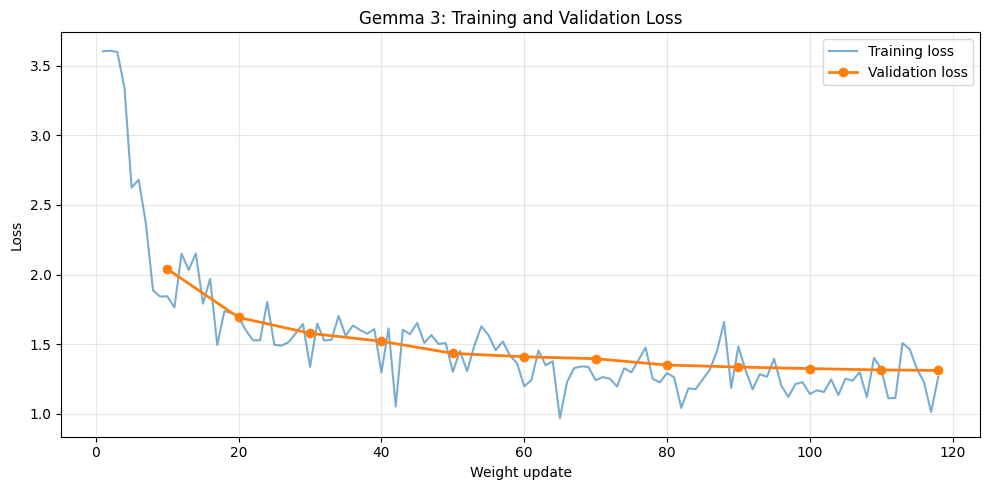

In [47]:

import matplotlib.pyplot as plt

# Create lists for the graph.
training_steps = []
training_losses = []
validation_steps = []
validation_losses = []

# Read the saved progress from this training run.
for entry in trainer.state.log_history:
    if "loss" in entry:
        training_steps.append(entry["step"])
        training_losses.append(entry["loss"])

    if "eval_loss" in entry:
        validation_steps.append(entry["step"])
        validation_losses.append(entry["eval_loss"])

if not training_losses or not validation_losses:
    raise ValueError("Training or validation results are missing.")

# Create the graph.
plt.figure(figsize=(10, 5))

# Training loss is recorded after each weight update.
plt.plot(
    training_steps,
    training_losses,
    label="Training loss",
    alpha=0.6,
)

# Validation loss is recorded at each validation check.
plt.plot(
    validation_steps,
    validation_losses,
    label="Validation loss",
    marker="o",
    linewidth=2,
)

plt.title("Gemma 3: Training and Validation Loss")
plt.xlabel("Weight update")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### What the Results Mean

The model trained for 2 epochs, completing 118 weight updates.
It used 467 training examples and 52 separate validation examples.

Training loss fell overall. It moved up and down because each update
used different examples.

Validation loss fell from 2.0394 at the first recorded check to
1.3102 at the final check. This suggests the model improved on the
separate validation examples.

The validation loss did not start rising while training loss fell.
Therefore, these results show no clear sign of overfitting
(learning the training examples too closely and doing worse on
separate examples).

However, this graph alone cannot prove that the model answers new
questions correctly. We must also inspect its answers.

The full training run took about 16.14 minutes. The best recorded
checkpoint was checkpoint-118.

# 5-Inference (Test the Model’s Answers)
<a name="Inference"></a>
### Inference
Let's run the model via Unsloth native inference! According to the `Gemma-3` team, the recommended settings for inference are `temperature = 1.0, top_p = 0.95, top_k = 64`

Before asking the model anything, we’ll choose a validation question that does not also appear in the training data:

In [48]:
# Remember the question text used for training.
training_questions = set()

for row in dataset["train"]:
    training_questions.add(row["input"].strip())

# Check the validation questions against the training questions.
unseen_examples = []
overlap_count = 0

for row in dataset["validation"]:
    if row["input"].strip() in training_questions:
        overlap_count += 1
    else:
        unseen_examples.append(row)

print("Validation examples:", len(dataset["validation"]))
print("Questions also found in training:", overlap_count)
print("Examples available for this test:", len(unseen_examples))

if not unseen_examples:
    raise ValueError("No separate questions available for this test.")

# Choose one example for our first answer test.
test_example = unseen_examples[0]
test_question = test_example["input"]
expected_answer = test_example["output"]

print("\n=== TEST QUESTION ===")
print(test_question)

print("\n=== EXPECTED ANSWER ===")
print(expected_answer)

Validation examples: 52
Questions also found in training: 5
Examples available for this test: 47

=== TEST QUESTION ===
តើប័ណ្ណសមាជិកមានសុពលភាពប៉ុន្មានឆ្នាំ

=== EXPECTED ANSWER ===
ប័ណ្ណសមាជិក​មាន​សុពលភាព ៤ឆ្នាំ ចាប់ពី​ថ្ងៃ​ចេញ​អោយ​ប្រើប្រាស់។


In [50]:
import torch

# Prepare the trained model to produce answers.
FastModel.for_inference(model)

# Give the model only the selected question.
# Do not include expected_answer here.
messages = [
    {"role": "user", "content": test_question}
]

# Arrange the question in Gemma 3's conversation format.
prompt = text_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,  # Mark where the answer should begin.
)

# Convert the prompt to number IDs and send them to the GPU.
inputs = text_tokenizer(
    prompt,
    return_tensors="pt",
    add_special_tokens=False,  # The chat format already added its markers.
).to(model.device)

# Produce an answer without calculating training changes.
with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=256,  # Maximum length of the new answer.
        do_sample=False,     # Choose tokens without random sampling.
    )

# Keep only the new answer, excluding the question.
prompt_length = inputs["input_ids"].shape[1]
answer_ids = outputs[0, prompt_length:]

model_answer = text_tokenizer.decode(
    answer_ids,
    skip_special_tokens=True,
)

print("=== QUESTION ===")
print(test_question)

print("\n=== MODEL ANSWER ===")
print(model_answer)

print("\n=== EXPECTED ANSWER ===")
print(expected_answer)

=== QUESTION ===
តើប័ណ្ណសមាជិកមានសុពលភាពប៉ុន្មានឆ្នាំ

=== MODEL ANSWER ===
ប័ណ្ណសមាជិកមានសុពលភាព ៥ឆ្នាំ។

=== EXPECTED ANSWER ===
ប័ណ្ណសមាជិក​មាន​សុពលភាព ៤ឆ្នាំ ចាប់ពី​ថ្ងៃ​ចេញ​អោយ​ប្រើប្រាស់។


 You can also use a `TextStreamer` for continuous inference - so you can see the generation token by token, instead of waiting the whole time!

In [51]:
from transformers import TextStreamer

# Choose the second example from our 47 separate examples.
test_example = unseen_examples[1]
test_question = test_example["input"]
expected_answer = test_example["output"]

# Send only the question to the model.
messages = [
    {"role": "user", "content": test_question}
]

prompt = text_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = text_tokenizer(
    prompt,
    return_tensors="pt",
    add_special_tokens=False,
).to(model.device)

# Display new answer text as the model produces it.
streamer = TextStreamer(
    text_tokenizer,
    skip_prompt=True,
    skip_special_tokens=True,
)

print("=== QUESTION ===")
print(test_question)

print("\n=== MODEL ANSWER ===")

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=256,
        do_sample=False,
        streamer=streamer,
    )

print("\n=== EXPECTED ANSWER ===")
print(expected_answer)

=== QUESTION ===
តើលក្ខណសម្បត្តិអតិថិជនបែបណា ដើម្បីទទួលបានសេវាភតិសន្យាហរិញ្ញវត្ថុ

=== MODEL ANSWER ===
អតិថិជនត្រូវមានអាយុចាប់ពី ១៨ ឆ្នាំឡើងទៅ និងមានអត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ ឬអត្តសញ្ញាណប័ណ្ណសញ្ជាតិផ្សេងទៀតដែលមានសុពលភាពយ៉ាងតិច ៣ខែ និងមានអាសយដ្ឋានជាក់លាក់នៅកម្ពុជា។

=== EXPECTED ANSWER ===
អតិថិជនត្រូវមានលក្ខណសម្បត្តិដូចខាងក្រោម៖ \n ជាពលរដ្ឋសកម្ម ឬជានីតិជន។ \n មានមុខរបរ និងប្រភពចំណូលដែលមាននិរន្តរភាព មានលទ្ធភាពបង់ថ្លៃឈ្នួលទាន់ពេលវេលា និងយល់ព្រមបង់ថ្លៃឈ្នួលដល់ការិយាល័យធនាគារ អេស៊ីលីដា ភីអិលស៊ី។ \n មានប្រវត្តិ កេរ្តិ៍ឈ្មោះ អត្តចរិតល្អ និងមានចេតនាបង់ថ្លៃឈ្នួលរហូតដល់ចប់កិច្ចព្រមព្រៀង។ \n មានទីលំនៅអចិន្រ្តៃយ៏ដែលបញ្ជាក់ពីអាជ្ញាធរក្នុងតំបន់ ដូចជាមានសៀវភៅគ្រួសារ សៀវភៅស្នាក់នៅ អត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ ឬលិខិតផ្សេងទៀតដែលអាចប្រើជំនួសបាន។ \n ធានាផ្តល់ព័ត៍មានត្រឹមត្រូវ ច្បាស់លាស់ គ្រប់គ្រាន់ និងទាន់ពេលវេលាជូនធនាគារ។ \n មិនជាប់ពិរុទ្ធដែលពាក់ព័ន្ធនឹងបទល្មើសផ្សេងៗ។ \n យល់ច្បាស់រាល់ប្រការ លក្ខខណ្ឌនៃគោលការណ៍ និងនីតិវិធីភតិសន្យាហរិញ្ញវត្ថុរបស់ធនាគារ អេស៊ីលីដា ភីអិលស៊ី។ \n មានអាជីវកម្មស្របច្បាប់ មិនស្ថ

In [52]:
# This tests the first five of our 47 separate examples, including the two already tested. It stores every result together so we can review them consistently.

import torch

FastModel.for_inference(model)

test_results = []
max_answer_tokens = 256

for number, example in enumerate(unseen_examples[:5], start=1):
    question = example["input"]
    expected = example["output"]

    # Give the model only the question.
    messages = [
        {"role": "user", "content": question}
    ]

    prompt = text_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = text_tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_answer_tokens,
            do_sample=False,
        )

    # Remove the question from the generated result.
    prompt_length = inputs["input_ids"].shape[1]
    answer_ids = outputs[0, prompt_length:]

    answer = text_tokenizer.decode(
        answer_ids,
        skip_special_tokens=True,
    )

    # Flag answers that reached our length limit.
    limit_reached = len(answer_ids) >= max_answer_tokens

    # Keep the result in notebook memory for later review.
    test_results.append({
        "number": number,
        "question": question,
        "model_answer": answer,
        "expected_answer": expected,
        "length_limit_reached": limit_reached,
        "review": "Not reviewed",
    })

    print(f"\n========== EXAMPLE {number} ==========")
    print("QUESTION:", question)
    print("\nMODEL ANSWER:", answer)
    print("\nEXPECTED ANSWER:", expected)
    print("\nReached answer length limit:", limit_reached)

print("\nFinished testing:", len(test_results), "examples")



========== EXAMPLE 1 ==========
QUESTION: តើប័ណ្ណសមាជិកមានសុពលភាពប៉ុន្មានឆ្នាំ

MODEL ANSWER: ប័ណ្ណសមាជិកមានសុពលភាព ៥ឆ្នាំ។

EXPECTED ANSWER: ប័ណ្ណសមាជិក​មាន​សុពលភាព ៤ឆ្នាំ ចាប់ពី​ថ្ងៃ​ចេញ​អោយ​ប្រើប្រាស់។

Reached answer length limit: False

========== EXAMPLE 2 ==========
QUESTION: តើលក្ខណសម្បត្តិអតិថិជនបែបណា ដើម្បីទទួលបានសេវាភតិសន្យាហរិញ្ញវត្ថុ

MODEL ANSWER: អតិថិជនត្រូវមានអាយុចាប់ពី ១៨ ឆ្នាំឡើងទៅ និងមានអត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ ឬអត្តសញ្ញាណប័ណ្ណសញ្ជាតិផ្សេងទៀតដែលមានសុពលភាពយ៉ាងតិច ៣ខែ និងមានអាសយដ្ឋានជាក់លាក់នៅកម្ពុជា។

EXPECTED ANSWER: អតិថិជនត្រូវមានលក្ខណសម្បត្តិដូចខាងក្រោម៖ \n ជាពលរដ្ឋសកម្ម ឬជានីតិជន។ \n មានមុខរបរ និងប្រភពចំណូលដែលមាននិរន្តរភាព មានលទ្ធភាពបង់ថ្លៃឈ្នួលទាន់ពេលវេលា និងយល់ព្រមបង់ថ្លៃឈ្នួលដល់ការិយាល័យធនាគារ អេស៊ីលីដា ភីអិលស៊ី។ \n មានប្រវត្តិ កេរ្តិ៍ឈ្មោះ អត្តចរិតល្អ និងមានចេតនាបង់ថ្លៃឈ្នួលរហូតដល់ចប់កិច្ចព្រមព្រៀង។ \n មានទីលំនៅអចិន្រ្តៃយ៏ដែលបញ្ជាក់ពីអាជ្ញាធរក្នុងតំបន់ ដូចជាមានសៀវភៅគ្រួសារ សៀវភៅស្នាក់នៅ អត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ ឬលិខិតផ្សេងទៀតដែលអាចប្រើជំនួសបាន។ \n ធាន

## A.Test is the model still give the same answer or not if we keep the same input 

In [53]:
import torch
from collections import Counter

FastModel.for_inference(model)

# Ask the same question 100 times.
consistency_question = unseen_examples[0]["input"]
consistency_expected = unseen_examples[0]["output"]
number_of_runs = 100

# Prepare the same input once and reuse it.
messages = [
    {"role": "user", "content": consistency_question}
]

prompt = text_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = text_tokenizer(
    prompt,
    return_tensors="pt",
    add_special_tokens=False,
).to(model.device)

prompt_length = inputs["input_ids"].shape[1]
consistency_answers = []

for run_number in range(1, number_of_runs + 1):
    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False,
            num_beams=1,
        )

    # Keep only the answer.
    answer_ids = outputs[0, prompt_length:]

    answer = text_tokenizer.decode(
        answer_ids,
        skip_special_tokens=True,
    ).strip()

    consistency_answers.append(answer)

    # Show progress after every 10 answers.
    if run_number % 10 == 0:
        print(f"Completed: {run_number}/{number_of_runs}")

# Count how often each answer appeared.
consistency_counts = Counter(consistency_answers)

print("\n=== CONSISTENCY RESULTS ===")
print("Question:", consistency_question)
print("Total runs:", len(consistency_answers))
print("Different answers:", len(consistency_counts))
print("All answers identical:", len(consistency_counts) == 1)

for answer, count in consistency_counts.most_common():
    print(f"\nAppeared {count}/{number_of_runs} times:")
    print(answer)

print("\nExpected answer:")
print(consistency_expected)

Completed: 10/100
Completed: 20/100
Completed: 30/100
Completed: 40/100
Completed: 50/100
Completed: 60/100
Completed: 70/100
Completed: 80/100
Completed: 90/100
Completed: 100/100

=== CONSISTENCY RESULTS ===
Question: តើប័ណ្ណសមាជិកមានសុពលភាពប៉ុន្មានឆ្នាំ
Total runs: 100
Different answers: 1
All answers identical: True

Appeared 100/100 times:
ប័ណ្ណសមាជិកមានសុពលភាព ៥ឆ្នាំ។

Expected answer:
ប័ណ្ណសមាជិក​មាន​សុពលភាព ៤ឆ្នាំ ចាប់ពី​ថ្ងៃ​ចេញ​អោយ​ប្រើប្រាស់។


#### We learned four things:

1. Consistency is not correctness. The model can repeat the same wrong fact reliably.
2. This is expected with do_sample=False. We kept the same question, model, and settings, without random token selection.
3. Repeating a question does not teach the model. These runs generated answers; they did not update its weights or correct the mistake.
4. This is one question tested repeatedly, not 100 different knowledge checks. It cannot tell us the model’s overall accuracy.


#### Under the same generation settings, the model returned the same answer in all 100 runs. However, that answer disagreed with the dataset’s reference. The test demonstrates repeatability for this question, but does not demonstrate factual correctness.

## B-Ask 5 diff question in but in the same meaning

This asks five versions of the same question. check whether the model keeps the same fact when the wording changes.

In [54]:
import torch

FastModel.for_inference(model)

# Different wordings of the membership-card question.
paraphrases = [
    consistency_question,
    "ប័ណ្ណសមាជិកអាចប្រើបានរយៈពេលប៉ុន្មានឆ្នាំ?",
    "សុពលភាពរបស់ប័ណ្ណសមាជិកមានរយៈពេលប៉ុន្មានឆ្នាំ?",
    "តើប័ណ្ណសមាជិកអាចប្រើប្រាស់បានប៉ុន្មានឆ្នាំ?",
    "ប័ណ្ណសមាជិកមានរយៈពេលសុពលភាពប៉ុន្មានឆ្នាំ?",
]

paraphrase_results = []

for number, question in enumerate(paraphrases, start=1):
    # Send only the question, without the expected answer.
    messages = [
        {"role": "user", "content": question}
    ]

    prompt = text_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = text_tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
    ).to(model.device)

    # Keep the same settings used in the 100-run test.
    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False,
            num_beams=1,
        )

    prompt_length = inputs["input_ids"].shape[1]
    answer_ids = outputs[0, prompt_length:]

    answer = text_tokenizer.decode(
        answer_ids,
        skip_special_tokens=True,
    ).strip()

    limit_reached = len(answer_ids) >= 256

    # Keep the results for our report.
    paraphrase_results.append({
        "number": number,
        "question": question,
        "model_answer": answer,
        "expected_answer": consistency_expected,
        "length_limit_reached": limit_reached,
    })

    print(f"\n=== QUESTION VERSION {number} ===")
    print(question)
    print("\nMODEL ANSWER:")
    print(answer)
    print("Reached answer length limit:", limit_reached)

print("\n=== EXPECTED ANSWER FOR ALL FIVE ===")
print(consistency_expected)


=== QUESTION VERSION 1 ===
តើប័ណ្ណសមាជិកមានសុពលភាពប៉ុន្មានឆ្នាំ

MODEL ANSWER:
ប័ណ្ណសមាជិកមានសុពលភាព ៥ឆ្នាំ។
Reached answer length limit: False

=== QUESTION VERSION 2 ===
ប័ណ្ណសមាជិកអាចប្រើបានរយៈពេលប៉ុន្មានឆ្នាំ?

MODEL ANSWER:
ប័ណ្ណសមាជិកអាចប្រើបានរយៈពេល ៥ឆ្នាំ។
Reached answer length limit: False

=== QUESTION VERSION 3 ===
សុពលភាពរបស់ប័ណ្ណសមាជិកមានរយៈពេលប៉ុន្មានឆ្នាំ?

MODEL ANSWER:
ប័ណ្ណសមាជិកមានសុពលភាពរយៈពេល ៣ឆ្នាំ។
Reached answer length limit: False

=== QUESTION VERSION 4 ===
តើប័ណ្ណសមាជិកអាចប្រើប្រាស់បានប៉ុន្មានឆ្នាំ?

MODEL ANSWER:
ប័ណ្ណសមាជិកអាចប្រើប្រាស់បាន ៥ឆ្នាំ។
Reached answer length limit: False

=== QUESTION VERSION 5 ===
ប័ណ្ណសមាជិកមានរយៈពេលសុពលភាពប៉ុន្មានឆ្នាំ?

MODEL ANSWER:
ប័ណ្ណសមាជិកមានសុពលភាព ៥ឆ្នាំ។
Reached answer length limit: False

=== EXPECTED ANSWER FOR ALL FIVE ===
ប័ណ្ណសមាជិក​មាន​សុពលភាព ៤ឆ្នាំ ចាប់ពី​ថ្ងៃ​ចេញ​អោយ​ប្រើប្រាស់។


### None of the five answers matches the reference. None reached the answer-length limit, so these mistakes were not caused by cutting the answers short.

### Together, our two tests show:

- Same exact question: the model repeated “5 years” in all 100 runs.
- Same meaning, different wording: one version changed the answer to “3 years.”
- Correctness: the model never gave the reference’s “4 years” in these tests.

### So the model is repeatable for an unchanged input, but its factual answer is sensitive to wording. The 100 identical replies did not prove that it understood the fact.

> ### The model repeated one answer consistently for identical input. However, changing the question’s wording changed the stated fact. All tested versions disagreed with the reference answer, showing that repeatability does not guarantee factual correctness.

# 6. Saving, loading fineturned models
<a name="Save"></a>
### Saving, loading finetuned models
To save the final model as LoRA adapters, either use Huggingface's `push_to_hub` for an online save or `save_pretrained` for a local save.

**[NOTE]** This ONLY saves the LoRA adapters, and not the full model. To save to 16bit or GGUF, scroll down!

In [58]:
import shutil
from pathlib import Path

# Save the trained adapter and processing tools.
save_path = Path(
    "/content/outputs/tp4_gemma3-ep2/final_adapter"
)

model.save_pretrained(str(save_path))
tokenizer.save_pretrained(str(save_path))

# Create one ZIP containing the saved folder.
zip_path = Path(
    shutil.make_archive(
        "/content/tp4_gemma3_ep2_adapter",
        "zip",
        root_dir=str(save_path.parent),
        base_dir=save_path.name,
    )
)

print("ZIP created:", zip_path.exists())
print("ZIP location:", zip_path)
print(f"ZIP size: {zip_path.stat().st_size / 1024**2:.2f} MiB")

Unsloth: Restored added_tokens_decoder metadata in /content/outputs/tp4_gemma3-ep2/final_adapter/tokenizer_config.json.


ZIP created: True
ZIP location: /content/tp4_gemma3_ep2_adapter.zip
ZIP size: 60.20 MiB


In [59]:
from pathlib import Path

# Find the folder containing our saved training changes.
save_path = Path(
    "/content/outputs/tp4_gemma3-ep2/final_adapter"
)

if not save_path.is_dir():
    raise FileNotFoundError("Saved folder not found. Run Cell 77 first.")

print("=== SAVED FILES ===")

# Show each file and its size.
for file in sorted(save_path.iterdir()):
    if file.is_file():
        size_mb = file.stat().st_size / 1024**2
        print(f"{file.name}: {size_mb:.2f} MiB")

print("\n=== REQUIRED MODEL FILES ===")
print(
    "Adapter settings:",
    (save_path / "adapter_config.json").is_file(),
)
print(
    "Adapter weights:",
    (save_path / "adapter_model.safetensors").is_file(),
)


=== SAVED FILES ===
README.md: 0.01 MiB
adapter_config.json: 0.00 MiB
adapter_model.safetensors: 56.91 MiB
chat_template.jinja: 0.00 MiB
processor_config.json: 0.00 MiB
tokenizer.json: 31.84 MiB
tokenizer.model: 4.47 MiB
tokenizer_config.json: 1.10 MiB

=== REQUIRED MODEL FILES ===
Adapter settings: True
Adapter weights: True


Now if you want to load the LoRA adapters we just saved for inference, set `False` to `True`:

In [1]:
from pathlib import Path
from unsloth import FastModel

# Location of our saved training changes.
adapter_path = Path(
    "/content/outputs/tp4_gemma3-ep2/final_adapter"
)

if not adapter_path.is_dir():
    raise FileNotFoundError("The saved adapter folder was not found.")

# Load Gemma together with our saved adapter.
model, tokenizer = FastModel.from_pretrained(
    model_name=str(adapter_path),
    max_seq_length=2048,
    load_in_4bit=True,
    load_in_8bit=False,
    full_finetuning=False,
)

# Use the text tool inside the processor, if it has one.
if hasattr(tokenizer, "tokenizer"):
    text_tokenizer = tokenizer.tokenizer
else:
    text_tokenizer = tokenizer

# Prepare the model to answer questions.
FastModel.for_inference(model)

print("Saved model loaded successfully.")
print("Model type:", type(model).__name__)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.2: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

In [3]:
# ask the saved model our previous question using the same settings#

import torch

# Use the same question we tested before saving.
reload_question = "តើប័ណ្ណសមាជិកមានសុពលភាពប៉ុន្មានឆ្នាំ"

messages = [
    {"role": "user", "content": reload_question}
]

# Add the chat format Gemma expects.
prompt = text_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

# Turn the text into numbers and send them to the model's device.
inputs = text_tokenizer(
    prompt,
    return_tensors="pt",
    add_special_tokens=False,
).to(model.device)

# Generate an answer without training or random sampling.
with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=256,
        do_sample=False,
        num_beams=1,
    )

# Keep only the new answer, without the question.
prompt_length = inputs["input_ids"].shape[1]
answer_ids = outputs[0, prompt_length:]

reload_answer = text_tokenizer.decode(
    answer_ids,
    skip_special_tokens=True,
).strip()

print("=== QUESTION ===")
print(reload_question)

print("\n=== ANSWER AFTER LOADING ===")
print(reload_answer)

print("\n=== ANSWER BEFORE SAVING ===")
print("ប័ណ្ណសមាជិកមានសុពលភាព ៥ឆ្នាំ។")

print("\n=== DATASET REFERENCE ===")
print("ប័ណ្ណសមាជិក​មាន​សុពលភាព ៤ឆ្នាំ ចាប់ពី​ថ្ងៃ​ចេញ​អោយ​ប្រើប្រាស់។")

=== QUESTION ===
តើប័ណ្ណសមាជិកមានសុពលភាពប៉ុន្មានឆ្នាំ

=== ANSWER AFTER LOADING ===
ប័ណ្ណសមាជិកមានសុពលភាព ៥ឆ្នាំ។

=== ANSWER BEFORE SAVING ===
ប័ណ្ណសមាជិកមានសុពលភាព ៥ឆ្នាំ។

=== DATASET REFERENCE ===
ប័ណ្ណសមាជិក​មាន​សុពលភាព ៤ឆ្នាំ ចាប់ពី​ថ្ងៃ​ចេញ​អោយ​ប្រើប្រាស់។


### Save and Load Test

The saved adapter loaded successfully.

For the same question and generation settings, the model gave
the same answer before saving and after loading.

However, it answered “5 years,” while the dataset reference
says “4 years.” Saving and loading kept this behavior,
including the wrong answer.

# 7.Saving to float16 for VLLM (optional)

We also support saving to `float16` directly for deployment! We save it in the folder `gemma-3-finetune`. Set `if False` to `if True` to let it run!

In [ ]:
if False: # Change to True to save finetune!
    model.save_pretrained_merged("gemma-3-finetune", tokenizer)

If you want to upload / push to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [ ]:
if False: # Change to True to upload finetune
    model.push_to_hub_merged(
        "HF_ACCOUNT/gemma-3-finetune", tokenizer,
        token = "hf_..."
    )

In [ ]:
if False: # Change to True to save to GGUF
    model.save_pretrained_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # For now only Q8_0, BF16, F16 supported
    )

Likewise, if you want to instead push to GGUF to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [ ]:
if False: # Change to True to upload GGUF
    model.push_to_hub_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # Only Q8_0, BF16, F16 supported
        repo_id = "HF_ACCOUNT/gemma-finetune-gguf",
        token = "hf_...",
    )